In [ ]:

import os

print("Current folder:", os.getcwd())
print("Files:", os.listdir())


Current folder: /content
Files: ['.config', '2025_LoL_esports_match_data_from_OraclesElixir.csv', '2024_LoL_esports_match_data_from_OraclesElixir.csv', '2026_LoL_esports_match_data_from_OraclesElixir.csv', 'sample_data']


In [ ]:
import pandas as pd

# 세 연도의 데이터 합치기
df_2024 = pd.read_csv("2024_LoL_esports_match_data_from_OraclesElixir.csv", low_memory=False)
df_2025 = pd.read_csv("2025_LoL_esports_match_data_from_OraclesElixir.csv", low_memory=False)
df_2026 = pd.read_csv("2026_LoL_esports_match_data_from_OraclesElixir.csv", low_memory=False)

df = pd.concat([df_2024, df_2025, df_2026], ignore_index=True)

# 팀 단위 기록만 추출
team_df = df[df["position"] == "team"].copy()

print("전체 데이터:", df.shape)
print("팀 데이터:", team_df.shape)

display(
    team_df[
        ["gameid", "date", "league", "teamname", "side", "result"]
    ].head(10)
)

전체 데이터: (361260, 165)
팀 데이터: (60210, 165)


,gameid,date,league,teamname,side,result
10,10660-10660_game_1,2024-01-01 05:13:15,DCup,LNG Esports,Blue,0
11,10660-10660_game_1,2024-01-01 05:13:15,DCup,Rare Atom,Red,1
22,10660-10660_game_2,2024-01-01 06:03:26,DCup,LNG Esports,Blue,0
23,10660-10660_game_2,2024-01-01 06:03:26,DCup,Rare Atom,Red,1
34,10660-10660_game_3,2024-01-01 06:54:35,DCup,LNG Esports,Blue,1
35,10660-10660_game_3,2024-01-01 06:54:35,DCup,Rare Atom,Red,0
46,10660-10660_game_4,2024-01-01 07:35:57,DCup,Rare Atom,Blue,1
47,10660-10660_game_4,2024-01-01 07:35:57,DCup,LNG Esports,Red,0
58,10661-10661_game_1,2024-01-01 08:45:42,DCup,JD Gaming,Blue,1
59,10661-10661_game_1,2024-01-01 08:45:42,DCup,Top Esports,Red,0


In [ ]:

# 1. Count team records per game
teams_per_game = team_df.groupby("gameid").size()

print("Games with exactly 2 teams:",
      (teams_per_game == 2).sum())

print("Games with an incorrect number of teams:",
      (teams_per_game != 2).sum())

# 2. Check whether each game has exactly one winner
wins_per_game = team_df.groupby("gameid")["result"].sum()

print("\nGames with exactly 1 winner:",
      (wins_per_game == 1).sum())

print("Games with invalid results:",
      (wins_per_game != 1).sum())

# 3. Check missing values in important columns
important_cols = [
    "gameid", "date", "league",
    "teamname", "side", "result"
]

print("\nMissing values:")
print(team_df[important_cols].isna().sum())


Games with exactly 2 teams: 30105
Games with an incorrect number of teams: 0

Games with exactly 1 winner: 30104
Games with invalid results: 1

Missing values:
gameid      0
date        0
league      0
teamname    0
side        0
result      0
dtype: int64


In [ ]:

# Find the game IDs with invalid winner records
invalid_game_ids = wins_per_game[
    wins_per_game != 1
].index

# Display the records for those games
invalid_games = team_df[
    team_df["gameid"].isin(invalid_game_ids)
]

display(
    invalid_games[
        ["gameid", "date", "league",
         "teamname", "side", "result",
         "datacompleteness"]
    ]
)


,gameid,date,league,teamname,side,result,datacompleteness
12586,LOLTMNT01_52116,2024-02-08 20:00:29,ESLOL,A One Man Army,Blue,0,complete
12587,LOLTMNT01_52116,2024-02-08 20:00:29,ESLOL,Once Upon A Team,Red,0,complete


In [ ]:

# Keep only games with exactly one winning team
valid_game_ids = wins_per_game[
    wins_per_game == 1
].index

clean_df = team_df[
    team_df["gameid"].isin(valid_game_ids)
].copy()

# Reset the index
clean_df = clean_df.reset_index(drop=True)

print("Original games:", team_df["gameid"].nunique())
print("Clean games:", clean_df["gameid"].nunique())
print("Clean dataset shape:", clean_df.shape)


Original games: 30105
Clean games: 30104
Clean dataset shape: (60208, 165)


In [ ]:

# Select the columns needed for match-level data
match_columns = [
    "gameid", "date", "league",
    "teamname", "side", "result"
]

# Separate Blue and Red team records
blue_df = clean_df[
    clean_df["side"] == "Blue"
][match_columns].copy()

red_df = clean_df[
    clean_df["side"] == "Red"
][match_columns].copy()

# Rename columns for each side
blue_df = blue_df.rename(columns={
    "teamname": "blue_team",
    "result": "blue_win"
})

red_df = red_df.rename(columns={
    "teamname": "red_team",
    "result": "red_win"
})

# Merge the two team records into one match
match_df = blue_df.merge(
    red_df[["gameid", "red_team", "red_win"]],
    on="gameid",
    how="inner",
    validate="one_to_one"
)

# Sort matches chronologically
match_df["date"] = pd.to_datetime(match_df["date"])
match_df = match_df.sort_values(["date", "gameid"]).reset_index(drop=True)

print("Match dataset shape:", match_df.shape)
print("Unique games:", match_df["gameid"].nunique())

display(match_df.head(10))


Match dataset shape: (30104, 8)
Unique games: 30104


,gameid,date,league,blue_team,side,blue_win,red_team,red_win
0,10660-10660_game_1,2024-01-01 05:13:15,DCup,LNG Esports,Blue,0,Rare Atom,1
1,10660-10660_game_2,2024-01-01 06:03:26,DCup,LNG Esports,Blue,0,Rare Atom,1
2,10660-10660_game_3,2024-01-01 06:54:35,DCup,LNG Esports,Blue,1,Rare Atom,0
3,10660-10660_game_4,2024-01-01 07:35:57,DCup,Rare Atom,Blue,1,LNG Esports,0
4,10661-10661_game_1,2024-01-01 08:45:42,DCup,JD Gaming,Blue,1,Top Esports,0
5,10661-10661_game_2,2024-01-01 09:44:10,DCup,Top Esports,Blue,1,JD Gaming,0
6,10661-10661_game_3,2024-01-01 10:45:21,DCup,JD Gaming,Blue,1,Top Esports,0
7,10661-10661_game_4,2024-01-01 11:40:41,DCup,Top Esports,Blue,1,JD Gaming,0
8,10661-10661_game_5,2024-01-01 12:24:41,DCup,JD Gaming,Blue,1,Top Esports,0
9,10662-10662_game_1,2024-01-03 09:12:49,DCup,Ninjas in Pyjamas,Blue,0,Bilibili Gaming,1


In [ ]:

# Remove redundant columns
match_df = match_df.drop(columns=["side", "red_win"])

print("Final match dataset shape:", match_df.shape)

display(match_df.head())


Final match dataset shape: (30104, 6)


,gameid,date,league,blue_team,blue_win,red_team
0,10660-10660_game_1,2024-01-01 05:13:15,DCup,LNG Esports,0,Rare Atom
1,10660-10660_game_2,2024-01-01 06:03:26,DCup,LNG Esports,0,Rare Atom
2,10660-10660_game_3,2024-01-01 06:54:35,DCup,LNG Esports,1,Rare Atom
3,10660-10660_game_4,2024-01-01 07:35:57,DCup,Rare Atom,1,LNG Esports
4,10661-10661_game_1,2024-01-01 08:45:42,DCup,JD Gaming,1,Top Esports


In [ ]:

# Extract the year from the match date
match_df["year"] = match_df["date"].dt.year

# Count matches per year
year_counts = match_df["year"].value_counts().sort_index()

print("Matches by year:")
print(year_counts)


Matches by year:
year
2024    10203
2025    10044
2026     9857
Name: count, dtype: int64


In [ ]:

# Top 15 leagues by number of matches
league_counts = match_df["league"].value_counts().head(15)

print("Top 15 leagues:")
print(league_counts)


Top 15 leagues:
league
LPL     2196
LCKC    1544
LCK     1539
EM      1362
LAS     1334
NACL    1044
LEC      985
LJL      885
PRM      864
LFL      830
AL       795
PCS      685
NLC      668
TCL      640
LCP      574
Name: count, dtype: int64


In [ ]:

# Calculate the overall Blue-side win rate
blue_win_rate = match_df["blue_win"].mean()

print(f"Overall Blue-side win rate: {blue_win_rate:.2%}")

# Blue-side win rate by year
print("\nBlue-side win rate by year:")
print(
    match_df.groupby("year")["blue_win"]
    .agg(["count", "mean"])
)


Overall Blue-side win rate: 53.28%

Blue-side win rate by year:
      count      mean
year                 
2024  10203  0.530726
2025  10044  0.532855
2026   9857  0.534848


In [ ]:
# Extract year from match date
match_df["year"] = match_df["date"].dt.year

# Count matches by year
year_counts = match_df["year"].value_counts().sort_index()

print("Matches by year:")
print(year_counts)

Matches by year:
year
2024    10203
2025    10044
2026     9857
Name: count, dtype: int64


In [ ]:
# Top 15 leagues by number of matches
league_counts = match_df["league"].value_counts().head(15)

print("Top 15 leagues:")
print(league_counts)

Top 15 leagues:
league
LPL     2196
LCKC    1544
LCK     1539
EM      1362
LAS     1334
NACL    1044
LEC      985
LJL      885
PRM      864
LFL      830
AL       795
PCS      685
NLC      668
TCL      640
LCP      574
Name: count, dtype: int64


In [ ]:
# Overall Blue-side win rate
blue_win_rate = match_df["blue_win"].mean()

print(f"Overall Blue-side win rate: {blue_win_rate:.2%}")

# Blue-side win rate by year
blue_win_by_year = (
    match_df.groupby("year")["blue_win"]
    .agg(["count", "mean"])
)

display(blue_win_by_year)

Overall Blue-side win rate: 53.28%


,count,mean
year,,
2024,10203,0.530726
2025,10044,0.532855
2026,9857,0.534848


In [ ]:

# Select only LCK and LEC matches
selected_leagues = ["LCK", "LEC"]

lol_df = match_df[
    match_df["league"].isin(selected_leagues)
].copy()

lol_df = lol_df.sort_values(
    ["date", "gameid"]
).reset_index(drop=True)

print("Total matches:", len(lol_df))

print("\nMatches by league:")
print(lol_df["league"].value_counts())

print("\nMatches by year and league:")
display(pd.crosstab(lol_df["year"], lol_df["league"]))

print("\nSample matches:")
display(lol_df.head())


Total matches: 2524

Matches by league:
league
LCK    1539
LEC     985
Name: count, dtype: int64

Matches by year and league:


league,LCK,LEC
year,,
2024,482,294
2025,555,308
2026,502,383



Sample matches:


,gameid,date,league,blue_team,blue_win,red_team,year
0,LOLTMNT06_13630,2024-01-13 16:10:20,LEC,Team BDS,0,G2 Esports,2024
1,LOLTMNT06_12701,2024-01-13 17:06:48,LEC,Rogue,0,SK Gaming,2024
2,LOLTMNT06_13667,2024-01-13 18:15:52,LEC,Karmine Corp,0,Fnatic,2024
3,LOLTMNT06_12743,2024-01-13 19:24:48,LEC,Team Vitality,0,GiantX,2024
4,LOLTMNT06_13695,2024-01-13 20:28:03,LEC,MAD Lions KOI,1,Team Heretics,2024


In [ ]:

# Elo model: initial parameters
INITIAL_ELO = 1500
K_FACTOR = 32 # can be adjusted later....

# Store each team's latest rating
ratings = {}

# Store the pre-match information
elo_records = []

for row in lol_df.itertuples(index=False):
    # Separate LCK and LEC rating systems
    blue_key = (row.league, row.blue_team)
    red_key = (row.league, row.red_team)

    # Rating BEFORE this match
    blue_elo = ratings.get(blue_key, INITIAL_ELO)
    red_elo = ratings.get(red_key, INITIAL_ELO)

    # Predicted probability of a Blue-side win
    blue_prob = 1 / (1 + 10 ** ((red_elo - blue_elo) / 400))

    # Save the prediction made before updating ratings
    elo_records.append({
        "gameid": row.gameid,
        "blue_elo_before": blue_elo,
        "red_elo_before": red_elo,
        "elo_blue_prob": blue_prob
    })

    # Update ratings AFTER observing the result
    ratings[blue_key] = blue_elo + K_FACTOR * (row.blue_win - blue_prob)
    ratings[red_key] = red_elo + K_FACTOR * ((1 - row.blue_win) - (1 - blue_prob))

# Merge Elo predictions into our match dataset
elo_df = pd.DataFrame(elo_records)

lol_df = lol_df.merge(
    elo_df,
    on="gameid",
    how="left",
    validate="one_to_one"
)

display(
    lol_df[
        ["date", "league", "blue_team", "red_team",
         "blue_win", "blue_elo_before",
         "red_elo_before", "elo_blue_prob"]
    ].head(10)
)


,date,league,blue_team,red_team,blue_win,blue_elo_before,red_elo_before,elo_blue_prob
0,2024-01-13 16:10:20,LEC,Team BDS,G2 Esports,0,1500.0,1500.0,0.500000
1,2024-01-13 17:06:48,LEC,Rogue,SK Gaming,0,1500.0,1500.0,0.500000
2,2024-01-13 18:15:52,LEC,Karmine Corp,Fnatic,0,1500.0,1500.0,0.500000
3,2024-01-13 19:24:48,LEC,Team Vitality,GiantX,0,1500.0,1500.0,0.500000
4,2024-01-13 20:28:03,LEC,MAD Lions KOI,Team Heretics,1,1500.0,1500.0,0.500000
5,2024-01-14 16:38:26,LEC,GiantX,Team BDS,0,1516.0,1484.0,0.545922
6,2024-01-14 17:39:16,LEC,MAD Lions KOI,SK Gaming,0,1516.0,1516.0,0.500000
7,2024-01-14 18:59:08,LEC,G2 Esports,Karmine Corp,1,1516.0,1484.0,0.545922
8,2024-01-14 19:55:50,LEC,Fnatic,Team Vitality,1,1516.0,1484.0,0.545922
9,2024-01-14 20:53:16,LEC,Rogue,Team Heretics,0,1484.0,1484.0,0.500000


In [ ]:

from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

# Evaluate the Elo model on 2026 matches
test_df = lol_df[lol_df["year"] == 2026].copy()

y_true = test_df["blue_win"]
y_prob = test_df["elo_blue_prob"]

# Convert probabilities into win/loss predictions
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
logloss = log_loss(y_true, y_prob, labels=[0, 1])
brier = brier_score_loss(y_true, y_prob)

print("2026 Elo Model Performance")
print("--------------------------")
print("Matches:", len(test_df))
print(f"Accuracy:    {accuracy:.2%}")
print(f"Log Loss:    {logloss:.4f}")
print(f"Brier Score: {brier:.4f}")


2026 Elo Model Performance
--------------------------
Matches: 885
Accuracy:    63.28%
Log Loss:    0.6453
Brier Score: 0.2263


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

# Use only 2024–2025 results to calculate the baseline
historical_df = lol_df[lol_df["year"] < 2026]

blue_baseline_prob = historical_df["blue_win"].mean()

# Evaluate on 2026
test_df = lol_df[lol_df["year"] == 2026].copy()
y_true = test_df["blue_win"]

models = {
    "50% Baseline": np.full(len(test_df), 0.5),
    "Blue-side Baseline": np.full(len(test_df), blue_baseline_prob),
    "Elo Model": test_df["elo_blue_prob"].to_numpy()
}

results = []

for name, probs in models.items():
    predictions = (probs >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Log Loss": log_loss(y_true, probs, labels=[0, 1]),
        "Brier Score": brier_score_loss(y_true, probs)
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)

print(f"Historical Blue-side win rate: {blue_baseline_prob:.2%}")


,Model,Accuracy,Log Loss,Brier Score
0,50% Baseline,56.61%,0.6931,0.2500
1,Blue-side Baseline,56.61%,0.6872,0.2470
2,Elo Model,63.28%,0.6453,0.2263


Historical Blue-side win rate: 52.90%


In [ ]:

from sklearn.metrics import log_loss, brier_score_loss, accuracy_score

def evaluate_elo(k_factor):
    ratings = {}
    records = []

    # Keep matches in chronological order
    data = lol_df.sort_values(["date", "gameid"])

    for row in data.itertuples(index=False):
        blue_key = (row.league, row.blue_team)
        red_key = (row.league, row.red_team)

        blue_elo = ratings.get(blue_key, 1500)
        red_elo = ratings.get(red_key, 1500)

        # Predict before updating ratings
        prob = 1 / (1 + 10 ** ((red_elo - blue_elo) / 400))

        if row.year == 2025:
            records.append((row.blue_win, prob))

        # Update after the match
        ratings[blue_key] = blue_elo + k_factor * (row.blue_win - prob)
        ratings[red_key] = red_elo + k_factor * (prob - row.blue_win)

    y_true = [r[0] for r in records]
    y_prob = [r[1] for r in records]

    return {
        "K": k_factor,
        "Accuracy": accuracy_score(
            y_true, [p >= 0.5 for p in y_prob]
        ),
        "Log Loss": log_loss(y_true, y_prob),
        "Brier Score": brier_score_loss(y_true, y_prob)
    }

k_results = pd.DataFrame([
    evaluate_elo(k) for k in [8, 16, 24, 32, 48, 64, 96]
])

display(
    k_results.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,K,Accuracy,Log Loss,Brier Score
0,8,66.86%,0.6219,0.2162
1,16,68.48%,0.6146,0.2128
2,24,67.21%,0.6139,0.2121
3,32,67.21%,0.6153,0.2123
4,48,66.86%,0.6216,0.2144
5,64,66.05%,0.6310,0.2178
6,96,63.27%,0.6549,0.2262


In [ ]:

# Selected using 2025 validation performance
BEST_K = 24

ratings = {}
predictions = []

# Process matches in chronological order
data = lol_df.sort_values(["date", "gameid"])

for row in data.itertuples(index=False):
    blue_key = (row.league, row.blue_team)
    red_key = (row.league, row.red_team)

    blue_elo = ratings.get(blue_key, 1500)
    red_elo = ratings.get(red_key, 1500)

    # Prediction BEFORE the match
    blue_prob = 1 / (1 + 10 ** ((red_elo - blue_elo) / 400))

    predictions.append({
        "gameid": row.gameid,
        "elo24_blue_prob": blue_prob
    })

    # Update ratings AFTER the result is known
    ratings[blue_key] = blue_elo + BEST_K * (row.blue_win - blue_prob)
    ratings[red_key] = red_elo + BEST_K * (blue_prob - row.blue_win)

# Add the updated probabilities to the match dataset
pred_df = pd.DataFrame(predictions)

lol_df = lol_df.merge(
    pred_df,
    on="gameid",
    how="left",
    validate="one_to_one"
)

print("Dataset shape:", lol_df.shape)

display(
    lol_df[
        ["year", "league", "blue_team",
         "red_team", "blue_win",
         "elo_blue_prob", "elo24_blue_prob"]
    ].head(10)
)


Dataset shape: (2524, 11)


,year,league,blue_team,red_team,blue_win,elo_blue_prob,elo24_blue_prob
0,2024,LEC,Team BDS,G2 Esports,0,0.500000,0.500000
1,2024,LEC,Rogue,SK Gaming,0,0.500000,0.500000
2,2024,LEC,Karmine Corp,Fnatic,0,0.500000,0.500000
3,2024,LEC,Team Vitality,GiantX,0,0.500000,0.500000
4,2024,LEC,MAD Lions KOI,Team Heretics,1,0.500000,0.500000
5,2024,LEC,GiantX,Team BDS,0,0.545922,0.534484
6,2024,LEC,MAD Lions KOI,SK Gaming,0,0.500000,0.500000
7,2024,LEC,G2 Esports,Karmine Corp,1,0.545922,0.534484
8,2024,LEC,Fnatic,Team Vitality,1,0.545922,0.534484
9,2024,LEC,Rogue,Team Heretics,0,0.500000,0.500000


In [ ]:

from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import pandas as pd

# Select 2026 matches
test_df = lol_df[lol_df["year"] == 2026].copy()

y_true = test_df["blue_win"]

results = []

for name, column in [
    ("Elo K=32", "elo_blue_prob"),
    ("Elo K=24", "elo24_blue_prob")
]:
    y_prob = test_df[column]
    y_pred = (y_prob >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Log Loss": log_loss(y_true, y_prob, labels=[0, 1]),
        "Brier Score": brier_score_loss(y_true, y_prob)
    })

comparison_df = pd.DataFrame(results)

display(
    comparison_df.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,Model,Accuracy,Log Loss,Brier Score
0,Elo K=32,63.28%,0.6453,0.2263
1,Elo K=24,63.05%,0.6395,0.2242


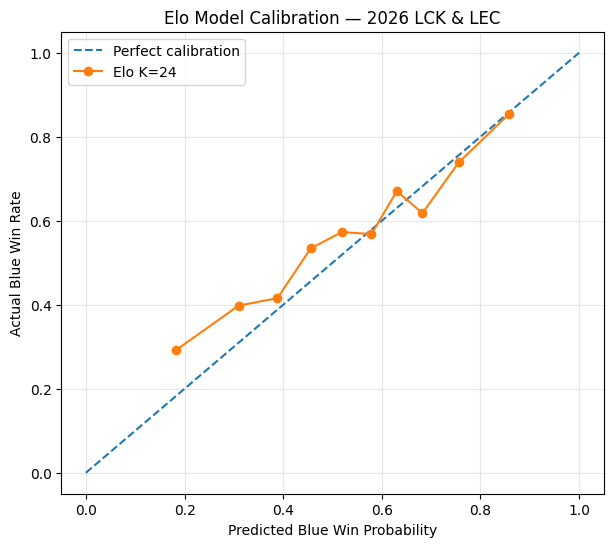

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Evaluate the selected K=24 model
test_df = lol_df[lol_df["year"] == 2026].copy()

y_true = test_df["blue_win"]
y_prob = test_df["elo24_blue_prob"]

# Divide predictions into 10 groups of similar size
fraction_positive, mean_predicted = calibration_curve(
    y_true,
    y_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

# Perfect calibration reference
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

# Our Elo model
plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Elo K=24"
)

plt.xlabel("Predicted Blue Win Probability")
plt.ylabel("Actual Blue Win Rate")
plt.title("Elo Model Calibration — 2026 LCK & LEC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

import pandas as pd

# 2026 matches, selected K=24 model
cal_df = lol_df[lol_df["year"] == 2026][
    ["blue_win", "elo24_blue_prob"]
].copy()

# Divide predicted probabilities into 10 equally sized groups
cal_df["probability_bin"] = pd.qcut(
    cal_df["elo24_blue_prob"],
    q=10,
    duplicates="drop"
)

# Compare predicted and observed probabilities
calibration_table = (
    cal_df.groupby("probability_bin", observed=True)
    .agg(
        matches=("blue_win", "size"),
        predicted_probability=("elo24_blue_prob", "mean"),
        actual_win_rate=("blue_win", "mean")
    )
    .reset_index()
)

calibration_table["difference"] = (
    calibration_table["actual_win_rate"]
    - calibration_table["predicted_probability"]
)

display(
    calibration_table.style.format({
        "predicted_probability": "{:.1%}",
        "actual_win_rate": "{:.1%}",
        "difference": "{:+.1%}"
    })
)


,probability_bin,matches,predicted_probability,actual_win_rate,difference
0,"(0.0627, 0.265]",89,18.3%,29.2%,+10.9%
1,"(0.265, 0.349]",88,30.9%,39.8%,+8.8%
2,"(0.349, 0.425]",89,38.8%,41.6%,+2.7%
3,"(0.425, 0.487]",88,45.6%,53.4%,+7.8%
4,"(0.487, 0.551]",89,51.9%,57.3%,+5.4%
5,"(0.551, 0.608]",88,57.9%,56.8%,-1.1%
6,"(0.608, 0.656]",88,63.0%,67.0%,+4.0%
7,"(0.656, 0.709]",89,68.2%,61.8%,-6.4%
8,"(0.709, 0.801]",88,75.6%,73.9%,-1.7%
9,"(0.801, 0.949]",89,85.8%,85.4%,-0.4%


In [ ]:

# Recalculate pre-match Elo ratings using K=24
ratings = {}
records = []

for row in lol_df.sort_values(["date", "gameid"]).itertuples(index=False):
    blue_key = (row.league, row.blue_team)
    red_key = (row.league, row.red_team)

    blue_elo = ratings.get(blue_key, 1500)
    red_elo = ratings.get(red_key, 1500)

    # Save ratings BEFORE the match
    records.append({
        "gameid": row.gameid,
        "blue_elo24_before": blue_elo,
        "red_elo24_before": red_elo
    })

    # Calculate win probability
    prob = 1 / (1 + 10 ** ((red_elo - blue_elo) / 400))

    # Update ratings AFTER the match
    ratings[blue_key] = blue_elo + 24 * (row.blue_win - prob)
    ratings[red_key] = red_elo + 24 * (prob - row.blue_win)

# Add the new columns without changing existing data
elo24_ratings = pd.DataFrame(records)

lol_df = lol_df.merge(
    elo24_ratings,
    on="gameid",
    how="left",
    validate="one_to_one"
)

print("Dataset shape:", lol_df.shape)

display(
    lol_df[
        ["blue_team", "red_team",
         "blue_elo24_before", "red_elo24_before"]
    ].head()
)
#K=24!!!!

Dataset shape: (2524, 13)


,blue_team,red_team,blue_elo24_before,red_elo24_before
0,Team BDS,G2 Esports,1500.0,1500.0
1,Rogue,SK Gaming,1500.0,1500.0
2,Karmine Corp,Fnatic,1500.0,1500.0
3,Team Vitality,GiantX,1500.0,1500.0
4,MAD Lions KOI,Team Heretics,1500.0,1500.0


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import log_loss, brier_score_loss

# Use the Elo ratings calculated before each match
# with K=24, but test different Blue-side adjustments.
validation_df = lol_df[lol_df["year"] == 2025].copy()

H_values = [-40, -20, 0, 20, 40, 60]

results = []

for H in H_values:
    blue_prob = 1 / (
        1 + 10 ** (
            (validation_df["red_elo_before"]
             - validation_df["blue_elo_before"] - H) / 400
        )
    )

    results.append({
        "Blue Bonus H": H,
        "Log Loss": log_loss(
            validation_df["blue_win"], blue_prob
        ),
        "Brier Score": brier_score_loss(
            validation_df["blue_win"], blue_prob
        )
    })

side_results = pd.DataFrame(results)

display(
    side_results.style.format({
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,Blue Bonus H,Log Loss,Brier Score
0,-40,0.6359,0.2209
1,-20,0.6242,0.2161
2,0,0.6153,0.2123
3,20,0.6090,0.2098
4,40,0.6055,0.2084
5,60,0.6047,0.2081


In [ ]:

from sklearn.metrics import log_loss, brier_score_loss
import pandas as pd

# 2025 validation data
validation_df = lol_df[lol_df["year"] == 2025].copy()

# Different Blue-side Elo bonuses
H_values = [-40, -20, 0, 20, 40, 60, 80]

results = []

for H in H_values:

    # Use PRE-MATCH ratings calculated with K=24
    blue_prob = 1 / (
        1 + 10 ** (
            (
                validation_df["red_elo24_before"]
                - validation_df["blue_elo24_before"]
                - H
            ) / 400
        )
    )

    results.append({
        "Blue Bonus H": H,
        "Log Loss": log_loss(
            validation_df["blue_win"], blue_prob
        ),
        "Brier Score": brier_score_loss(
            validation_df["blue_win"], blue_prob
        )
    })

side_results_k24 = pd.DataFrame(results)

display(
    side_results_k24.style.format({
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,Blue Bonus H,Log Loss,Brier Score
0,-40,0.6337,0.2206
1,-20,0.6224,0.2158
2,0,0.6139,0.2121
3,20,0.6081,0.2097
4,40,0.6051,0.2084
5,60,0.6049,0.2084
6,80,0.6074,0.2097


In [ ]:

from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import pandas as pd
import numpy as np

# 2026 evaluation data
test_df = lol_df[lol_df["year"] == 2026].copy()

# Model A: Elo only
prob_elo = test_df["elo24_blue_prob"]

# Model B: Elo + Blue-side bonus
H = 60

prob_elo_side = 1 / (
    1 + 10 ** (
        (
            test_df["red_elo24_before"]
            - test_df["blue_elo24_before"]
            - H
        ) / 400
    )
)

results = []

for name, probs in [
    ("Elo K=24, H=0", prob_elo),
    ("Elo K=24, H=60", prob_elo_side)
]:
    preds = (probs >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(test_df["blue_win"], preds),
        "Log Loss": log_loss(test_df["blue_win"], probs),
        "Brier Score": brier_score_loss(test_df["blue_win"], probs)
    })

comparison = pd.DataFrame(results)

display(
    comparison.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,Model,Accuracy,Log Loss,Brier Score
0,"Elo K=24, H=0",63.05%,0.6395,0.2242
1,"Elo K=24, H=60",63.95%,0.6415,0.2250


In [ ]:

from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import pandas as pd

test_df = lol_df[lol_df["year"] == 2026].copy()

# Existing Elo K=24 predictions
test_df["prob_H0"] = test_df["elo24_blue_prob"]

# Add the fixed Blue-side adjustment
test_df["prob_H60"] = 1 / (
    1 + 10 ** (
        (
            test_df["red_elo24_before"]
            - test_df["blue_elo24_before"]
            - 60
        ) / 400
    )
)

results = []

for league, group in test_df.groupby("league"):
    for name, column in [
        ("H=0", "prob_H0"),
        ("H=60", "prob_H60")
    ]:
        probs = group[column]
        preds = (probs >= 0.5).astype(int)

        results.append({
            "League": league,
            "Model": name,
            "Matches": len(group),
            "Accuracy": accuracy_score(group["blue_win"], preds),
            "Log Loss": log_loss(group["blue_win"], probs, labels=[0, 1]),
            "Brier Score": brier_score_loss(group["blue_win"], probs)
        })

league_comparison = pd.DataFrame(results)

display(
    league_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,League,Model,Matches,Accuracy,Log Loss,Brier Score
0,LCK,H=0,502,62.75%,0.6419,0.2251
1,LCK,H=60,502,64.14%,0.6425,0.2250
2,LEC,H=0,383,63.45%,0.6364,0.2230
3,LEC,H=60,383,63.71%,0.6402,0.2251


In [ ]:

import pandas as pd

# Convert match-level data into team-level records
blue_games = lol_df[
    ["gameid", "date", "league",
     "blue_team", "blue_win"]
].rename(columns={
    "blue_team": "team",
    "blue_win": "win"
})

red_games = lol_df[
    ["gameid", "date", "league",
     "red_team", "blue_win"]
].rename(columns={
    "red_team": "team"
})

red_games["win"] = 1 - red_games["blue_win"]
red_games = red_games.drop(columns="blue_win")

# Combine Blue and Red team match histories
team_history = pd.concat(
    [blue_games, red_games],
    ignore_index=True
)

# Order matches chronologically for each team
team_history = team_history.sort_values(
    ["league", "team", "date", "gameid"]
).reset_index(drop=True)

# Count the number of previous matches
team_history["previous_games"] = (
    team_history.groupby(["league", "team"])
    .cumcount()
)

# Calculate win rate over the previous 5 matches
team_history["recent5_winrate"] = (
    team_history.groupby(["league", "team"])["win"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=5, min_periods=1
        ).mean()
    )
)

# Inspect a few records
display(
    team_history[
        ["date", "league", "team",
         "win", "previous_games",
         "recent5_winrate"]
    ].head(15)
)


,date,league,team,win,previous_games,recent5_winrate
0,2024-01-18 10:57:08,LCK,BNK FEARX,0,0,NaN
1,2024-01-18 11:54:26,LCK,BNK FEARX,0,1,0.000000
2,2024-01-20 06:07:32,LCK,BNK FEARX,1,2,0.000000
3,2024-01-20 06:57:59,LCK,BNK FEARX,1,3,0.333333
4,2024-01-24 08:06:21,LCK,BNK FEARX,0,4,0.500000
5,2024-01-24 09:00:49,LCK,BNK FEARX,0,5,0.400000
6,2024-01-26 11:25:59,LCK,BNK FEARX,1,6,0.400000
7,2024-01-26 12:29:48,LCK,BNK FEARX,0,7,0.600000
8,2024-01-26 13:22:20,LCK,BNK FEARX,1,8,0.400000
9,2024-02-01 10:35:28,LCK,BNK FEARX,1,9,0.400000


In [ ]:

# Prepare Blue team's recent form
blue_form = team_history[
    ["gameid", "team", "recent5_winrate"]
].rename(columns={
    "team": "blue_team",
    "recent5_winrate": "blue_recent5"
})

# Prepare Red team's recent form
red_form = team_history[
    ["gameid", "team", "recent5_winrate"]
].rename(columns={
    "team": "red_team",
    "recent5_winrate": "red_recent5"
})

# Merge Blue team history
lol_df = lol_df.merge(
    blue_form,
    on=["gameid", "blue_team"],
    how="left",
    validate="one_to_one"
)

# Merge Red team history
lol_df = lol_df.merge(
    red_form,
    on=["gameid", "red_team"],
    how="left",
    validate="one_to_one"
)

print("Dataset shape:", lol_df.shape)

display(
    lol_df[
        ["date", "league", "blue_team", "red_team",
         "blue_recent5", "red_recent5",
         "blue_win"]
    ].tail(10)
)


Dataset shape: (2524, 15)


,date,league,blue_team,red_team,blue_recent5,red_recent5,blue_win
2514,2026-09-18 15:17:45,LEC,Movistar KOI,Natus Vincere,0.6,0.6,0
2515,2026-09-18 16:24:03,LEC,Movistar KOI,Natus Vincere,0.4,0.6,1
2516,2026-09-18 17:15:57,LEC,Movistar KOI,Natus Vincere,0.6,0.6,1
2517,2026-09-18 18:12:05,LEC,Movistar KOI,Natus Vincere,0.8,0.4,1
2518,2026-09-19 15:14:52,LEC,Karmine Corp,Movistar KOI,0.4,0.8,0
2519,2026-09-19 16:20:50,LEC,Movistar KOI,Karmine Corp,0.8,0.2,1
2520,2026-09-19 17:16:53,LEC,Movistar KOI,Karmine Corp,1.0,0.2,1
2521,2026-09-20 15:13:50,LEC,G2 Esports,Movistar KOI,0.8,1.0,1
2522,2026-09-20 16:17:50,LEC,G2 Esports,Movistar KOI,0.8,0.8,1
2523,2026-09-20 17:13:10,LEC,G2 Esports,Movistar KOI,0.8,0.6,1


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Create pre-match features
model_df = lol_df.copy()

model_df["elo_diff"] = (
    model_df["blue_elo24_before"]
    - model_df["red_elo24_before"]
)

model_df["recent5_diff"] = (
    model_df["blue_recent5"]
    - model_df["red_recent5"]
)

# Use neutral value for teams without previous match history
model_df["recent5_diff"] = model_df["recent5_diff"].fillna(0)

features = ["elo_diff", "recent5_diff"]

# Split data chronologically
train = model_df[model_df["year"] == 2024]
valid = model_df[model_df["year"] == 2025]
test = model_df[model_df["year"] == 2026]

# Train only on 2024
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(train[features], train["blue_win"])

# Evaluate on 2025 validation data
valid_probs = model.predict_proba(valid[features])[:, 1]

print("2025 Logistic Regression Performance")
print("------------------------------------")
print(f"Accuracy: {accuracy_score(valid['blue_win'], valid_probs >= 0.5):.2%}")
print(f"Log Loss: {log_loss(valid['blue_win'], valid_probs):.4f}")
print(f"Brier Score: {brier_score_loss(valid['blue_win'], valid_probs):.4f}")


2025 Logistic Regression Performance
------------------------------------
Accuracy: 68.02%
Log Loss: 0.6122
Brier Score: 0.2112


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import pandas as pd

feature_sets = {
    "Logistic: Elo only": ["elo_diff"],
    "Logistic: Elo + Recent 5": ["elo_diff", "recent5_diff"]
}

results = []

for name, features in feature_sets.items():

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )

    # Fit on 2024 data only
    model.fit(train[features], train["blue_win"])

    # Predict 2025 games
    probs = model.predict_proba(valid[features])[:, 1]
    predictions = (probs >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(valid["blue_win"], predictions),
        "Log Loss": log_loss(valid["blue_win"], probs),
        "Brier Score": brier_score_loss(valid["blue_win"], probs)
    })

feature_comparison = pd.DataFrame(results)

display(
    feature_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,Model,Accuracy,Log Loss,Brier Score
0,Logistic: Elo only,68.71%,0.6117,0.2102
1,Logistic: Elo + Recent 5,68.02%,0.6122,0.2112


In [ ]:

# Check that matches and team histories are correctly aligned

print("Duplicate game IDs:",
      lol_df["gameid"].duplicated().sum())

print("Chronological order:",
      lol_df["date"].is_monotonic_increasing)

print("Missing Elo ratings:",
      lol_df[
          ["blue_elo24_before", "red_elo24_before"]
      ].isna().sum().sum())

print("Recent-form values outside 0-1:",
      (
          (team_history["recent5_winrate"].dropna() < 0)
          | (team_history["recent5_winrate"].dropna() > 1)
      ).sum())

print("Games with identical timestamps:",
      lol_df["date"].duplicated().sum())


Duplicate game IDs: 0
Chronological order: True
Missing Elo ratings: 0
Recent-form values outside 0-1: 0
Games with identical timestamps: 0


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import pandas as pd

results = []

# Existing Elo model
elo_probs = test["elo24_blue_prob"]

results.append({
    "Model": "Original Elo K=24",
    "Accuracy": accuracy_score(test["blue_win"], elo_probs >= 0.5),
    "Log Loss": log_loss(test["blue_win"], elo_probs),
    "Brier Score": brier_score_loss(test["blue_win"], elo_probs)
})

# Logistic Regression models
for name, features in {
    "Logistic: Elo only": ["elo_diff"],
    "Logistic: Elo + Recent 5": ["elo_diff", "recent5_diff"]
}.items():

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )

    model.fit(train[features], train["blue_win"])

    probs = model.predict_proba(test[features])[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(test["blue_win"], probs >= 0.5),
        "Log Loss": log_loss(test["blue_win"], probs),
        "Brier Score": brier_score_loss(test["blue_win"], probs)
    })

test_comparison = pd.DataFrame(results)

display(
    test_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,Model,Accuracy,Log Loss,Brier Score
0,Original Elo K=24,63.05%,0.6395,0.2242
1,Logistic: Elo only,64.07%,0.6516,0.2277
2,Logistic: Elo + Recent 5,63.73%,0.6478,0.2266


In [ ]:

# Examine team names across seasons

blue_teams = lol_df[
    ["league", "year", "blue_team"]
].rename(columns={"blue_team": "team"})

red_teams = lol_df[
    ["league", "year", "red_team"]
].rename(columns={"red_team": "team"})

all_teams = pd.concat(
    [blue_teams, red_teams],
    ignore_index=True
).drop_duplicates()

team_names = (
    all_teams.groupby(["league", "team"])["year"]
    .apply(lambda years: ", ".join(map(str, sorted(years.unique()))))
    .reset_index(name="Years")
    .sort_values(["league", "team"])
)

display(team_names)
print("Unique league-team names:", len(team_names))


,league,team,Years
0,LCK,BNK FEARX,"2024, 2025, 2026"
1,LCK,DN SOOPers,"2024, 2025, 2026"
2,LCK,Dplus Kia,"2024, 2025, 2026"
3,LCK,Gen.G,"2024, 2025, 2026"
4,LCK,HANJIN BRION,"2024, 2025, 2026"
5,LCK,Hanwha Life Esports,"2024, 2025, 2026"
6,LCK,KT Rolster,"2024, 2025, 2026"
7,LCK,Kiwoom DRX,"2024, 2025, 2026"
8,LCK,Nongshim RedForce,"2024, 2025, 2026"
9,LCK,T1,"2024, 2025, 2026"


Unique league-team names: 25


In [ ]:

# Check first recorded match for teams affected by renaming

teams_to_check = [
    "MAD Lions KOI",
    "Movistar KOI",
    "Team BDS",
    "Shifters",
    "Rogue",
    "Natus Vincere"
]

records = []

for team in teams_to_check:

    games = lol_df[
        (lol_df["blue_team"] == team) |
        (lol_df["red_team"] == team)
    ].sort_values("date")

    if games.empty:
        continue

    first = games.iloc[0]

    team_elo = (
        first["blue_elo24_before"]
        if first["blue_team"] == team
        else first["red_elo24_before"]
    )

    records.append({
        "Team": team,
        "First Match": first["date"],
        "Starting Elo": team_elo,
        "Total Games": len(games)
    })

display(pd.DataFrame(records))


,Team,First Match,Starting Elo,Total Games
0,MAD Lions KOI,2024-01-13 20:28:03,1500.0,75
1,Movistar KOI,2025-01-18 19:59:46,1500.0,179
2,Team BDS,2024-01-13 16:10:20,1500.0,131
3,Shifters,2026-01-17 17:06:08,1500.0,54
4,Rogue,2024-01-13 17:06:48,1500.0,58
5,Natus Vincere,2025-08-02 15:14:26,1500.0,83


In [ ]:

# Create a new dataset without changing the original
lol_df_v2 = lol_df.copy()

# Map historical team names to one consistent identity
team_name_map = {
    "MAD Lions KOI": "Movistar KOI",
    "Team BDS": "Shifters"
}

for column in ["blue_team", "red_team"]:
    lol_df_v2[column] = (
        lol_df_v2[column]
        .replace(team_name_map)
    )

# Check the updated team names
print("Original team names:")
print(sorted(
    set(lol_df["blue_team"]) | set(lol_df["red_team"])
))

print("\nUpdated team names:")
print(sorted(
    set(lol_df_v2["blue_team"]) | set(lol_df_v2["red_team"])
))

print("\nOriginal rows:", len(lol_df))
print("Updated rows:", len(lol_df_v2))

# MAD Lions KOI = Movistar KOI / Team BDS = Shifters


Original team names:
['BNK FEARX', 'DN SOOPers', 'Dplus Kia', 'Fnatic', 'G2 Esports', 'Gen.G', 'GiantX', 'HANJIN BRION', 'Hanwha Life Esports', 'KT Rolster', 'Karmine Corp', 'Karmine Corp Blue', 'Kiwoom DRX', 'Los Ratones', 'MAD Lions KOI', 'Movistar KOI', 'Natus Vincere', 'Nongshim RedForce', 'Rogue', 'SK Gaming', 'Shifters', 'T1', 'Team BDS', 'Team Heretics', 'Team Vitality']

Updated team names:
['BNK FEARX', 'DN SOOPers', 'Dplus Kia', 'Fnatic', 'G2 Esports', 'Gen.G', 'GiantX', 'HANJIN BRION', 'Hanwha Life Esports', 'KT Rolster', 'Karmine Corp', 'Karmine Corp Blue', 'Kiwoom DRX', 'Los Ratones', 'Movistar KOI', 'Natus Vincere', 'Nongshim RedForce', 'Rogue', 'SK Gaming', 'Shifters', 'T1', 'Team Heretics', 'Team Vitality']

Original rows: 2524
Updated rows: 2524


In [ ]:

# Recalculate Elo using unified team names

K = 24
INITIAL_ELO = 1500

ratings_v2 = {}
elo_v2_records = []

for row in lol_df_v2.sort_values(
    ["date", "gameid"]
).itertuples(index=False):

    blue_key = (row.league, row.blue_team)
    red_key = (row.league, row.red_team)

    blue_elo = ratings_v2.get(blue_key, INITIAL_ELO)
    red_elo = ratings_v2.get(red_key, INITIAL_ELO)

    # Predict BEFORE updating ratings
    blue_prob = 1 / (
        1 + 10 ** ((red_elo - blue_elo) / 400)
    )

    elo_v2_records.append({
        "gameid": row.gameid,
        "blue_elo_v2_before": blue_elo,
        "red_elo_v2_before": red_elo,
        "elo_v2_prob": blue_prob
    })

    # Update ratings AFTER the match
    ratings_v2[blue_key] = (
        blue_elo + K * (row.blue_win - blue_prob)
    )

    ratings_v2[red_key] = (
        red_elo + K * (blue_prob - row.blue_win)
    )

# Attach newly calculated predictions
elo_v2_df = pd.DataFrame(elo_v2_records)

lol_df_v2 = lol_df_v2.merge(
    elo_v2_df,
    on="gameid",
    how="left",
    validate="one_to_one"
)

print("Updated dataset shape:", lol_df_v2.shape)

print(
    "Missing new predictions:",
    lol_df_v2["elo_v2_prob"].isna().sum()
)

display(
    lol_df_v2[
        ["year", "league", "blue_team",
         "red_team", "elo_v2_prob"]
    ].tail(5)
)


Updated dataset shape: (2524, 18)
Missing new predictions: 0


,year,league,blue_team,red_team,elo_v2_prob
2519,2026,LEC,Movistar KOI,Karmine Corp,0.353165
2520,2026,LEC,Movistar KOI,Karmine Corp,0.394979
2521,2026,LEC,G2 Esports,Movistar KOI,0.653997
2522,2026,LEC,G2 Esports,Movistar KOI,0.675301
2523,2026,LEC,G2 Esports,Movistar KOI,0.694656


In [ ]:

from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import pandas as pd

results = []

for year in [2025, 2026]:

    data = lol_df_v2[lol_df_v2["year"] == year]

    models = {
        "V1: Original Elo": data["elo24_blue_prob"],
        "V2: Unified Team Names": data["elo_v2_prob"]
    }

    for name, probs in models.items():

        results.append({
            "Year": year,
            "Model": name,
            "Matches": len(data),
            "Accuracy": accuracy_score(
                data["blue_win"], probs >= 0.5
            ),
            "Log Loss": log_loss(
                data["blue_win"], probs
            ),
            "Brier Score": brier_score_loss(
                data["blue_win"], probs
            )
        })

comparison_v2 = pd.DataFrame(results)

display(
    comparison_v2.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,Year,Model,Matches,Accuracy,Log Loss,Brier Score
0,2025,V1: Original Elo,863,67.21%,0.6139,0.2121
1,2025,V2: Unified Team Names,863,67.21%,0.6140,0.2122
2,2026,V1: Original Elo,885,63.05%,0.6395,0.2242
3,2026,V2: Unified Team Names,885,63.39%,0.6388,0.2237


In [ ]:

# Check season boundaries in the cleaned dataset

season_boundaries = (
    lol_df_v2
    .groupby(["league", "year"])
    .agg(
        first_match=("date", "min"),
        last_match=("date", "max"),
        matches=("gameid", "count")
    )
    .reset_index()
)

display(season_boundaries)


,league,year,first_match,last_match,matches
0,LCK,2024,2024-01-17 08:20:00,2024-09-08 10:43:57,482
1,LCK,2025,2025-01-15 08:09:30,2025-09-28 08:21:35,555
2,LCK,2026,2026-01-14 08:13:43,2026-09-13 08:19:05,502
3,LEC,2024,2024-01-13 16:10:20,2024-09-01 19:16:56,294
4,LEC,2025,2025-01-18 17:09:08,2025-09-28 17:10:18,308
5,LEC,2026,2026-01-17 16:08:02,2026-09-20 17:13:10,383


In [ ]:

from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import pandas as pd

INITIAL_ELO = 1500
K = 24

def evaluate_seasonal_elo(alpha):
    ratings = {}
    previous_year = {}

    predictions = []
    actuals = []
    years = []

    # Process matches in chronological order
    for row in lol_df_v2.sort_values(
        ["date", "gameid"]
    ).itertuples(index=False):

        blue_key = (row.league, row.blue_team)
        red_key = (row.league, row.red_team)

        for key in [blue_key, red_key]:
            if key not in ratings:
                ratings[key] = INITIAL_ELO
                previous_year[key] = row.year

            elif previous_year[key] != row.year:
                # Regress previous season Elo toward 1500
                ratings[key] = (
                    INITIAL_ELO
                    + alpha * (ratings[key] - INITIAL_ELO)
                )
                previous_year[key] = row.year

        blue_elo = ratings[blue_key]
        red_elo = ratings[red_key]

        blue_prob = 1 / (
            1 + 10 ** ((red_elo - blue_elo) / 400)
        )

        predictions.append(blue_prob)
        actuals.append(row.blue_win)
        years.append(row.year)

        # Update only AFTER the game
        ratings[blue_key] += K * (row.blue_win - blue_prob)
        ratings[red_key] += K * (blue_prob - row.blue_win)

    result_df = pd.DataFrame({
        "year": years,
        "actual": actuals,
        "probability": predictions
    })

    validation = result_df[result_df["year"] == 2025]

    return {
        "Alpha": alpha,
        "Accuracy": accuracy_score(
            validation["actual"],
            validation["probability"] >= 0.5
        ),
        "Log Loss": log_loss(
            validation["actual"],
            validation["probability"]
        ),
        "Brier Score": brier_score_loss(
            validation["actual"],
            validation["probability"]
        )
    }

alphas = [0.0, 0.5, 0.75, 1.0]

seasonal_results = pd.DataFrame([
    evaluate_seasonal_elo(alpha)
    for alpha in alphas
])

display(
    seasonal_results.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,Alpha,Accuracy,Log Loss,Brier Score
0,0.000000,66.86%,0.6275,0.2190
1,0.500000,67.09%,0.6152,0.2132
2,0.750000,66.98%,0.6132,0.2122
3,1.000000,67.21%,0.6140,0.2122


In [ ]:

from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import pandas as pd

def compare_2026(alpha):
    ratings = {}
    previous_year = {}
    results = []

    for row in lol_df_v2.sort_values(
        ["date", "gameid"]
    ).itertuples(index=False):

        blue_key = (row.league, row.blue_team)
        red_key = (row.league, row.red_team)

        for key in [blue_key, red_key]:
            if key not in ratings:
                ratings[key] = 1500
                previous_year[key] = row.year
            elif previous_year[key] != row.year:
                ratings[key] = 1500 + alpha * (ratings[key] - 1500)
                previous_year[key] = row.year

        blue_elo = ratings[blue_key]
        red_elo = ratings[red_key]

        prob = 1 / (1 + 10 ** ((red_elo - blue_elo) / 400))

        if row.year == 2026:
            results.append({
                "actual": row.blue_win,
                "prob": prob
            })

        ratings[blue_key] = blue_elo + 24 * (row.blue_win - prob)
        ratings[red_key] = red_elo + 24 * (prob - row.blue_win)

    result = pd.DataFrame(results)

    return {
        "Alpha": alpha,
        "Accuracy": accuracy_score(result["actual"], result["prob"] >= 0.5),
        "Log Loss": log_loss(result["actual"], result["prob"]),
        "Brier Score": brier_score_loss(result["actual"], result["prob"])
    }

comparison = pd.DataFrame([
    compare_2026(1.0),
    compare_2026(0.75)
])

display(
    comparison.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,Alpha,Accuracy,Log Loss,Brier Score
0,1.000000,63.39%,0.6388,0.2237
1,0.750000,63.50%,0.6355,0.2227


In [ ]:

# Save game-by-game predictions from V3

ALPHA = 0.75
K = 24
ratings = {}
last_year = {}
predictions = []

for row in lol_df_v2.sort_values(
    ["date", "gameid"]
).itertuples(index=False):

    blue_key = (row.league, row.blue_team)
    red_key = (row.league, row.red_team)

    for key in [blue_key, red_key]:
        if key not in ratings:
            ratings[key] = 1500
            last_year[key] = row.year
        elif last_year[key] != row.year:
            ratings[key] = 1500 + ALPHA * (ratings[key] - 1500)
            last_year[key] = row.year

    blue_elo = ratings[blue_key]
    red_elo = ratings[red_key]

    prob = 1 / (1 + 10 ** ((red_elo - blue_elo) / 400))

    predictions.append({
        "gameid": row.gameid,
        "v3_blue_elo": blue_elo,
        "v3_red_elo": red_elo,
        "v3_blue_prob": prob
    })

    ratings[blue_key] = blue_elo + K * (row.blue_win - prob)
    ratings[red_key] = red_elo + K * (prob - row.blue_win)

v3_predictions = pd.DataFrame(predictions)

lol_df_v3 = lol_df_v2.merge(
    v3_predictions,
    on="gameid",
    how="left",
    validate="one_to_one"
)

print("V3 dataset shape:", lol_df_v3.shape)
print("Missing predictions:", lol_df_v3["v3_blue_prob"].isna().sum())

display(
    lol_df_v3[
        ["year", "league", "blue_team", "red_team",
         "v3_blue_prob", "blue_win"]
    ].tail(5)
)


V3 dataset shape: (2524, 21)
Missing predictions: 0


,year,league,blue_team,red_team,v3_blue_prob,blue_win
2519,2026,LEC,Movistar KOI,Karmine Corp,0.356959,1
2520,2026,LEC,Movistar KOI,Karmine Corp,0.398695,1
2521,2026,LEC,G2 Esports,Movistar KOI,0.647364,1
2522,2026,LEC,G2 Esports,Movistar KOI,0.669276,1
2523,2026,LEC,G2 Esports,Movistar KOI,0.689181,1


In [ ]:

import numpy as np

# Focus on 2026 exploratory evaluation
error_df = lol_df_v3[
    lol_df_v3["year"] == 2026
].copy()

# Probability assigned to the outcome that actually occurred
error_df["actual_outcome_prob"] = np.where(
    error_df["blue_win"] == 1,
    error_df["v3_blue_prob"],
    1 - error_df["v3_blue_prob"]
)

# Individual match log loss
error_df["match_log_loss"] = -np.log(
    error_df["actual_outcome_prob"]
)

# Identify the actual winner
error_df["actual_winner"] = np.where(
    error_df["blue_win"] == 1,
    error_df["blue_team"],
    error_df["red_team"]
)

# Show the 10 largest prediction errors
worst_10 = error_df.nlargest(
    10, "match_log_loss"
)[
    ["date", "league", "blue_team", "red_team",
     "v3_blue_prob", "actual_winner",
     "match_log_loss"]
]

display(
    worst_10.style.format({
        "v3_blue_prob": "{:.1%}",
        "match_log_loss": "{:.3f}"
    })
)


,date,league,blue_team,red_team,v3_blue_prob,actual_winner,match_log_loss
2413,2026-08-23 17:21:07,LEC,Shifters,Karmine Corp,9.4%,Shifters,2.368
2042,2026-04-30 08:55:13,LCK,Kiwoom DRX,Gen.G,10.7%,Kiwoom DRX,2.234
2153,2026-05-23 11:15:14,LCK,Hanwha Life Esports,Nongshim RedForce,85.9%,Nongshim RedForce,1.961
2025,2026-04-25 19:39:22,LEC,Shifters,Karmine Corp,14.8%,Shifters,1.911
1896,2026-04-03 08:10:24,LCK,KT Rolster,Gen.G,15.5%,KT Rolster,1.861
1942,2026-04-11 10:14:53,LCK,Dplus Kia,Gen.G,16.5%,Dplus Kia,1.800
2371,2026-08-16 17:11:28,LEC,Fnatic,G2 Esports,17.3%,Fnatic,1.752
2102,2026-05-10 10:31:52,LCK,Kiwoom DRX,Hanwha Life Esports,17.4%,Kiwoom DRX,1.751
1829,2026-02-21 10:03:38,LCK,Gen.G,BNK FEARX,82.5%,BNK FEARX,1.740
1667,2026-01-18 11:12:18,LCK,T1,Kiwoom DRX,82.2%,Kiwoom DRX,1.724


In [ ]:

import pandas as pd

# Use 2026 exploratory evaluation
data = lol_df_v3[lol_df_v3["year"] == 2026].copy()

# Blue-side team perspective
blue = data[
    ["league", "blue_team", "blue_win", "v3_blue_prob"]
].rename(columns={
    "blue_team": "team",
    "blue_win": "actual_win",
    "v3_blue_prob": "predicted_win_prob"
})

# Red-side team perspective
red = data[
    ["league", "red_team", "blue_win", "v3_blue_prob"]
].copy()

red["actual_win"] = 1 - red["blue_win"]
red["predicted_win_prob"] = 1 - red["v3_blue_prob"]

red = red.rename(columns={"red_team": "team"})
red = red[
    ["league", "team", "actual_win", "predicted_win_prob"]
]

# Combine both sides
team_results = pd.concat([blue, red], ignore_index=True)

# Calculate team-level prediction bias
team_summary = (
    team_results.groupby(["league", "team"])
    .agg(
        matches=("actual_win", "size"),
        actual_win_rate=("actual_win", "mean"),
        predicted_win_rate=("predicted_win_prob", "mean")
    )
    .reset_index()
)

team_summary["difference"] = (
    team_summary["actual_win_rate"]
    - team_summary["predicted_win_rate"]
)

# Sort by largest absolute difference
team_summary = team_summary.sort_values(
    "difference",
    key=abs,
    ascending=False
)

display(
    team_summary.style.format({
        "actual_win_rate": "{:.1%}",
        "predicted_win_rate": "{:.1%}",
        "difference": "{:+.1%}"
    })
)


,league,team,matches,actual_win_rate,predicted_win_rate,difference
14,LEC,Karmine Corp Blue,11,18.2%,44.4%,-26.2%
20,LEC,Team Heretics,55,25.5%,34.3%,-8.9%
10,LEC,Fnatic,60,41.7%,48.4%,-6.8%
17,LEC,Natus Vincere,75,50.7%,46.5%,+4.1%
13,LEC,Karmine Corp,104,66.3%,62.5%,+3.8%
19,LEC,Shifters,54,29.6%,33.3%,-3.7%
11,LEC,G2 Esports,89,70.8%,67.2%,+3.6%
21,LEC,Team Vitality,78,55.1%,52.0%,+3.2%
7,LCK,Kiwoom DRX,96,38.5%,41.1%,-2.6%
2,LCK,Dplus Kia,120,54.2%,52.0%,+2.1%


In [ ]:

from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import pandas as pd

league_results = []

for league, group in lol_df_v3[
    lol_df_v3["year"] == 2026
].groupby("league"):

    probs = group["v3_blue_prob"]
    actual = group["blue_win"]

    league_results.append({
        "League": league,
        "Matches": len(group),
        "Accuracy": accuracy_score(actual, probs >= 0.5),
        "Log Loss": log_loss(actual, probs),
        "Brier Score": brier_score_loss(actual, probs)
    })

league_performance = pd.DataFrame(league_results)

display(
    league_performance.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,League,Matches,Accuracy,Log Loss,Brier Score
0,LCK,502,63.15%,0.6374,0.2238
1,LEC,383,63.97%,0.6330,0.2213


In [ ]:

from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import pandas as pd

summary_rows = []

for year in [2025, 2026]:
    data = lol_df_v3[lol_df_v3["year"] == year]

    models = {
        "V1: Basic Elo": "elo24_blue_prob",
        "V2: Unified Teams": "elo_v2_prob",
        "V3: Seasonal Elo": "v3_blue_prob"
    }

    for model_name, column in models.items():
        probs = data[column]
        actual = data["blue_win"]

        summary_rows.append({
            "Year": year,
            "Model": model_name,
            "Matches": len(data),
            "Accuracy": accuracy_score(
                actual, probs >= 0.5
            ),
            "Log Loss": log_loss(actual, probs),
            "Brier Score": brier_score_loss(actual, probs)
        })

model_summary = pd.DataFrame(summary_rows)

display(
    model_summary.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)

# Save summary as CSV
model_summary.to_csv(
    "lol_elo_model_comparison.csv",
    index=False
)

print("Saved: lol_elo_model_comparison.csv")


,Year,Model,Matches,Accuracy,Log Loss,Brier Score
0,2025,V1: Basic Elo,863,67.21%,0.6139,0.2121
1,2025,V2: Unified Teams,863,67.21%,0.6140,0.2122
2,2025,V3: Seasonal Elo,863,66.98%,0.6132,0.2122
3,2026,V1: Basic Elo,885,63.05%,0.6395,0.2242
4,2026,V2: Unified Teams,885,63.39%,0.6388,0.2237
5,2026,V3: Seasonal Elo,885,63.50%,0.6355,0.2227


Saved: lol_elo_model_comparison.csv


In [ ]:

# Export match-level predictions for reproducible analysis

export_columns = [
    "gameid",
    "date",
    "year",
    "league",
    "blue_team",
    "red_team",
    "blue_win",
    "elo24_blue_prob",
    "elo_v2_prob",
    "v3_blue_prob"
]

predictions_export = lol_df_v3[
    export_columns
].copy()

# Save chronologically
predictions_export = predictions_export.sort_values(
    ["date", "gameid"]
)

predictions_export.to_csv(
    "lol_match_predictions.csv",
    index=False
)

print("Saved: lol_match_predictions.csv")
print("Shape:", predictions_export.shape)

display(predictions_export.head())


Saved: lol_match_predictions.csv
Shape: (2524, 10)


,gameid,date,year,league,blue_team,red_team,blue_win,elo24_blue_prob,elo_v2_prob,v3_blue_prob
0,LOLTMNT06_13630,2024-01-13 16:10:20,2024,LEC,Shifters,G2 Esports,0,0.5,0.5,0.5
1,LOLTMNT06_12701,2024-01-13 17:06:48,2024,LEC,Rogue,SK Gaming,0,0.5,0.5,0.5
2,LOLTMNT06_13667,2024-01-13 18:15:52,2024,LEC,Karmine Corp,Fnatic,0,0.5,0.5,0.5
3,LOLTMNT06_12743,2024-01-13 19:24:48,2024,LEC,Team Vitality,GiantX,0,0.5,0.5,0.5
4,LOLTMNT06_13695,2024-01-13 20:28:03,2024,LEC,Movistar KOI,Team Heretics,1,0.5,0.5,0.5


In [ ]:

# Keep historical and canonical team names separately

historical_names = lol_df[
    ["gameid", "blue_team", "red_team"]
].rename(columns={
    "blue_team": "blue_team_original",
    "red_team": "red_team_original"
})

final_predictions = lol_df_v3.merge(
    historical_names,
    on="gameid",
    how="left",
    validate="one_to_one"
)

final_predictions = final_predictions.rename(columns={
    "blue_team": "blue_team_canonical",
    "red_team": "red_team_canonical"
})

export_columns = [
    "gameid", "date", "year", "league",
    "blue_team_original", "red_team_original",
    "blue_team_canonical", "red_team_canonical",
    "blue_win",
    "elo24_blue_prob",
    "elo_v2_prob",
    "v3_blue_prob"
]

final_predictions = final_predictions[
    export_columns
].sort_values(["date", "gameid"])

final_predictions.to_csv(
    "lol_match_predictions_final.csv",
    index=False
)

print("Final dataset shape:", final_predictions.shape)
print("Saved: lol_match_predictions_final.csv")

display(final_predictions.head())


Final dataset shape: (2524, 12)
Saved: lol_match_predictions_final.csv


,gameid,date,year,league,blue_team_original,red_team_original,blue_team_canonical,red_team_canonical,blue_win,elo24_blue_prob,elo_v2_prob,v3_blue_prob
0,LOLTMNT06_13630,2024-01-13 16:10:20,2024,LEC,Team BDS,G2 Esports,Shifters,G2 Esports,0,0.5,0.5,0.5
1,LOLTMNT06_12701,2024-01-13 17:06:48,2024,LEC,Rogue,SK Gaming,Rogue,SK Gaming,0,0.5,0.5,0.5
2,LOLTMNT06_13667,2024-01-13 18:15:52,2024,LEC,Karmine Corp,Fnatic,Karmine Corp,Fnatic,0,0.5,0.5,0.5
3,LOLTMNT06_12743,2024-01-13 19:24:48,2024,LEC,Team Vitality,GiantX,Team Vitality,GiantX,0,0.5,0.5,0.5
4,LOLTMNT06_13695,2024-01-13 20:28:03,2024,LEC,MAD Lions KOI,Team Heretics,Movistar KOI,Team Heretics,1,0.5,0.5,0.5
